In [1]:
import pandas as pd
from io import StringIO

data = """order_id,date,product,category,quantity,unit_price,region
O001,2026-11-01,Milk,Dairy,2,60,Nairobi
O002,2026-11-01,Bread,Bakery,3,55,Nairobi
O003,2026-11-02,Milk,Dairy,1,60,Kiambu
O004,2026-11-02,Tea,Beverages,2,120,Nairobi
O005,2026-11-03,Bread,bakery,2,55,Kiambu
O006,2026-11-03,Rice,Grains,1,200,Nairobi
O007,2026-11-04,Milk, dairy ,3,60,Nakuru
O008,2026-11-04,Tea,Beverages,1,,Kiambu
O009,2026-11-05,Bread,Bakery,,55,Nairobi
O010,2026-11-05,Rice,Grains,2,200,Kiambu
O011,2026-11-06,Juice,Beverages,2,150,Nakuru
O012,2026-11-06,Juice,Beverages,1,150,Nairobi
O002,2026-11-01,Bread,Bakery,3,55,Nairobi
"""

df = pd.read_csv(StringIO(data))

print(df.head())

  order_id        date product   category  quantity  unit_price   region
0     O001  2026-11-01    Milk      Dairy       2.0        60.0  Nairobi
1     O002  2026-11-01   Bread     Bakery       3.0        55.0  Nairobi
2     O003  2026-11-02    Milk      Dairy       1.0        60.0   Kiambu
3     O004  2026-11-02     Tea  Beverages       2.0       120.0  Nairobi
4     O005  2026-11-03   Bread     bakery       2.0        55.0   Kiambu


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13 entries, 0 to 12
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   order_id    13 non-null     object 
 1   date        13 non-null     object 
 2   product     13 non-null     object 
 3   category    13 non-null     object 
 4   quantity    12 non-null     float64
 5   unit_price  12 non-null     float64
 6   region      13 non-null     object 
dtypes: float64(2), object(5)
memory usage: 860.0+ bytes


In [5]:
df.dtypes

order_id       object
date           object
product        object
category       object
quantity      float64
unit_price    float64
region         object
dtype: object

In [6]:
df.isna().sum()

order_id      0
date          0
product       0
category      0
quantity      1
unit_price    1
region        0
dtype: int64

In [7]:
df.isnull().sum()

order_id      0
date          0
product       0
category      0
quantity      1
unit_price    1
region        0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(1)

In [10]:
df.duplicated()

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12     True
dtype: bool

In [12]:
df.columns

Index(['order_id', 'date', 'product', 'category', 'quantity', 'unit_price',
       'region'],
      dtype='object')

In [13]:
#Find the unique products, categories and regions.
df["product"].unique()

array(['Milk', 'Bread', 'Tea', 'Rice', 'Juice'], dtype=object)

In [14]:
df['category'].unique()

array(['Dairy', 'Bakery', 'Beverages', 'bakery', 'Grains', ' dairy '],
      dtype=object)

In [15]:
df['region'].unique()

array(['Nairobi', 'Kiambu', 'Nakuru'], dtype=object)

In [20]:
#Remove exact duplicate records.
df.drop_duplicates(inplace=True)

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
#Standardize category names (for example, bakery and dairy)
df['category']=df['category'].str.strip().str.lower()

In [23]:
df['category'].unique()

array(['dairy', 'bakery', 'beverages', 'grains'], dtype=object)

In [25]:
#Fill the missing Tea unit price using the median price for Tea.
tea_median=df.loc[df['product']=='Tea',"unit_price"].median()
df.loc[(df['product']=='Tea')& (df['unit_price'].isna()),'unit_price']=tea_median

In [26]:
df['unit_price'].isna().sum()

np.int64(0)

In [27]:
#Remove the transaction with missing quantity and document why you removed it.
df.head(12)

,order_id,date,product,category,quantity,unit_price,region
0,O001,2026-11-01,Milk,dairy,2.0,60.0,Nairobi
1,O002,2026-11-01,Bread,bakery,3.0,55.0,Nairobi
2,O003,2026-11-02,Milk,dairy,1.0,60.0,Kiambu
3,O004,2026-11-02,Tea,beverages,2.0,120.0,Nairobi
4,O005,2026-11-03,Bread,bakery,2.0,55.0,Kiambu
5,O006,2026-11-03,Rice,grains,1.0,200.0,Nairobi
6,O007,2026-11-04,Milk,dairy,3.0,60.0,Nakuru
7,O008,2026-11-04,Tea,beverages,1.0,120.0,Kiambu
8,O009,2026-11-05,Bread,bakery,NaN,55.0,Nairobi
9,O010,2026-11-05,Rice,grains,2.0,200.0,Kiambu


In [30]:
df.dropna(subset=['quantity'],inplace=True)#Removed because you cannot guess the quantity or impute it and the quantity is required together with the unit price to get the total price

In [29]:
df.isna().sum()

order_id      0
date          0
product       0
category      0
quantity      0
unit_price    0
region        0
dtype: int64

In [31]:
#Create a new column called revenue.
df['revenue']=df['quantity']*df['unit_price']

In [32]:
df.head()

,order_id,date,product,category,quantity,unit_price,region,revenue
0,O001,2026-11-01,Milk,dairy,2.0,60.0,Nairobi,120.0
1,O002,2026-11-01,Bread,bakery,3.0,55.0,Nairobi,165.0
2,O003,2026-11-02,Milk,dairy,1.0,60.0,Kiambu,60.0
3,O004,2026-11-02,Tea,beverages,2.0,120.0,Nairobi,240.0
4,O005,2026-11-03,Bread,bakery,2.0,55.0,Kiambu,110.0


In [33]:
#Calculate total supermarket revenue.
total_revenue=df['revenue'].sum()

In [38]:
print("Total revenue:",total_revenue)

Total revenue: 2045.0


## EDA


In [41]:
#Which product generated the highest revenue?
revenue_products=df.groupby("product")['revenue'].sum().sort_values(ascending=False)
print(revenue_products)

product
Rice     600.0
Juice    450.0
Milk     360.0
Tea      360.0
Bread    275.0
Name: revenue, dtype: float64


In [44]:
Highest_revenue_product=df.groupby('product')['revenue'].sum().sort_values(ascending=False).head(1)
print(Highest_revenue_product)

product
Rice    600.0
Name: revenue, dtype: float64


In [45]:
#Which region generated the highest revenue?
Highest_revenue_region=df.groupby('region')['revenue'].sum().sort_values(ascending=False).head(1)
print("Region with the highest revenue",Highest_revenue_region)

Region with the highest revenue region
Nairobi    875.0
Name: revenue, dtype: float64


In [46]:
#Which product had the highest total quantity sold?
Highest_selling_product=df.groupby('product')["quantity"].sum().sort_values(ascending=False).head(1)
print("The product with the highest total quantity sold",Highest_selling_product)

The product with the highest total quantity sold product
Milk    6.0
Name: quantity, dtype: float64


In [49]:
#What was the average transaction revenue?
avg_revenue=df['revenue'].mean().round(2)
print("Average transaction revenue",avg_revenue)

Average transaction revenue 185.91


In [52]:
#Which category generated the highest revenue?
Highest_category_value=df.groupby('category')["revenue"].sum().sort_values(ascending=False).head(1)
print("The category with the highest revenue",Highest_category_value)

The category with the highest revenue category
beverages    810.0
Name: revenue, dtype: float64


In [55]:
#What was the total revenue per day?
df['date']=pd.to_datetime(df['date'])
print(df.groupby('date')['revenue'].sum().sort_index())


date
2026-11-01    285.0
2026-11-02    300.0
2026-11-03    310.0
2026-11-04    300.0
2026-11-05    400.0
2026-11-06    450.0
Name: revenue, dtype: float64


## Data Visualization

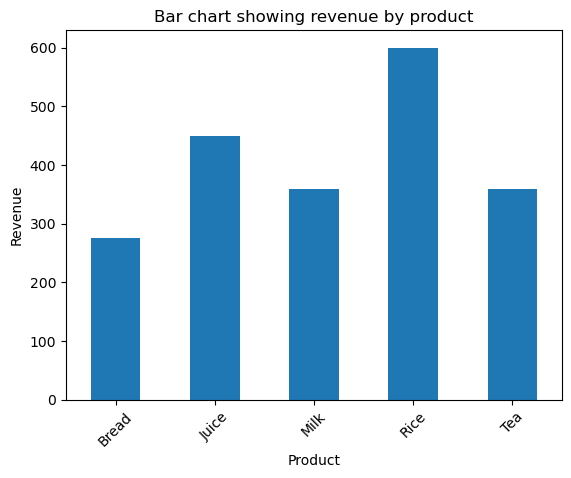

In [ ]:
import matplotlib.pyplot as plt
#A bar chart showing revenue by product.
revenue_by_product=df.groupby('product')["revenue"].sum()

revenue_by_product.plot(kind='bar')
plt.title("Bar chart showing revenue by product")
plt.xlabel('Product')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

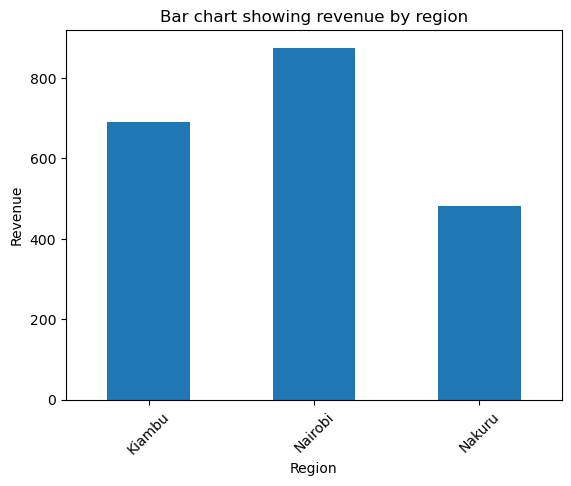

In [ ]:
#A bar chart showing revenue by region.
revenue_by_region=df.groupby('region')['revenue'].sum()
revenue_by_region.plot(kind='bar')
plt.title("Bar chart showing revenue by region")
plt.xlabel('Region')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

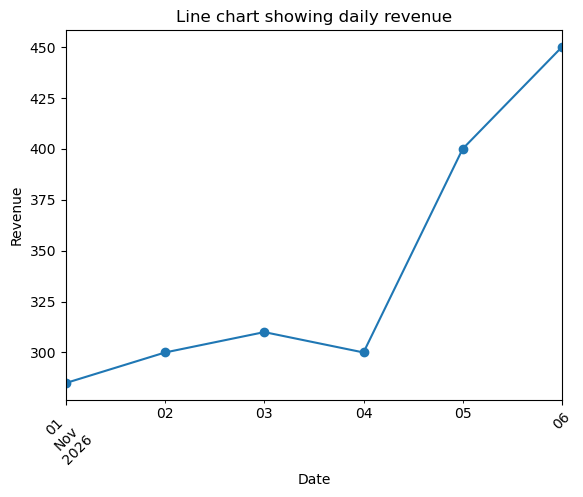

In [ ]:
#A line chart showing daily revenue.
daily_revenue=df.groupby("date")['revenue'].sum()
daily_revenue.plot(kind="line",marker='o')
plt.title('Line chart showing daily revenue')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.show()

**Observation**: Daily revenue increased from KES 285 on November 1 to KES 450 on November 6, with a slight decline on November 4.

**Interpretation**: The supermarket experienced an overall increase in revenue during the six-day observation period, although daily revenue was not consistently increasing.

**Recommendation**: The supermarket should investigate the factors contributing to the higher revenue on November 5 and 6. It should collect additional weeks of sales data to determine whether the pattern is recurring before making weekend inventory decisions.
